In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

In [2]:
# %% 1. Settings: two observed periods, four temperature-source regions
import numpy as np
import xarray as xr
from pathlib import Path

od_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
od_raw = Path("/scratch/leiff/MCA/amip_clean/data")
od_catalog_path = od_core / "stationarity/four_region_attribution/run_01/catalog.npy"
od_reference_path = od_core / "stationarity/window_length_comparison/run_01/observations.npy"
od_output_dir = od_core / "stationarity/observational_region_D/run_01"
od_save_path = od_output_dir / "observational_D.npy"
od_paths = {"T": od_raw / "ERA5/tas_194001-202412_g025.nc",
            "R": od_raw / "CERES/CERES_net_200003-202604_g025.nc"}
od_periods = {"2000_2014": ("2000-03", "2014-12"), "2000_2024": ("2000-03", "2024-12")}
od_regions = ["SEP", "SEPn", "SEPs", "WPWP"]
od_reuse = True                   # Reuse a complete archive with matching inputs/settings.
od_preprocessing_tag = "same_monthly_detrend_as_stationarity_v1"
od_vlim = 1.5                     # Same +/- limit for ALL eight maps; None uses their combined 98th percentile.
od_cmap, od_central_longitude = "RdBu_r", 210
od_save_figures = True

# Import/paste YOUR detrend_monthly_fast before cell 3. Each period has its own
# monthly detrending and local temperature SD. This is NOT the high-pass branch.
# The half-SEP panels are their own regional-mean indices, NOT area-scaled pieces.
# Later plot-only: run cells 1, 4, 5, 6; no raw data or detrending function needed.




In [3]:
# %% 2. Calculation and small input/save helpers
def observed_D_period(T_raw, R_raw, weights, regions, preprocess):
    """D_region(j) = Cov(A_region,Rj), where A_region = regional mean of Zi.

    Input fields: (time,lat,lon), consecutive months starting in March.
    Temperature is standardized locally over THIS period; R stays in W m-2.
    A is not standardized again. D is a covariance, not a slope divided by Var(A).
    """
    T_raw, R_raw, weights = [np.asarray(a, dtype=float) for a in [T_raw, R_raw, weights]]
    if T_raw.ndim != 3 or T_raw.shape != R_raw.shape or T_raw.shape[1:] != weights.shape or len(T_raw) < 36:
        raise ValueError("Expected matching (time,lat,lon) fields with at least three years.")
    if not np.isfinite(weights).all() or np.any(weights < 0) or weights.sum() <= 0:
        raise ValueError("Weights must be finite, nonnegative and have positive total area.")
    weights = weights / weights.sum()
    support = weights > 0
    masks = {}
    for region, mask in regions.items():
        mask = np.ma.asarray(mask, dtype=float).filled(np.nan)
        if mask.shape != weights.shape:
            raise ValueError(f"{region}: mask does not match the grid.")
        masks[region] = np.isfinite(mask) & (mask != 0) & support
        if not masks[region].any():
            raise ValueError(f"{region}: empty source region.")
    if np.any(masks["SEPn"] & masks["SEPs"]) or not np.array_equal(masks["SEPn"] | masks["SEPs"], masks["SEP"]):
        raise ValueError("SEP north/south must partition SEP without gaps or overlap.")
    source = np.logical_or.reduce(list(masks.values()))
    if not np.isfinite(T_raw[:, source]).all() or not np.isfinite(R_raw[:, support]).all():
        raise ValueError("Require complete source-region T and global R; no changing spatial masks.")

    # D needs local radiation everywhere, unlike the scalar-only I calculation.
    # Excluded cells get zero placeholders only during preprocessing. Copies
    # protect inputs from an in-place user function. Recenter before covariances.
    T = np.asarray(preprocess(np.where(source, T_raw, 0.)), dtype=float)
    R = np.asarray(preprocess(np.where(support, R_raw, 0.)), dtype=float)
    if T.shape != T_raw.shape or R.shape != R_raw.shape or not np.isfinite(T[:, source]).all() or not np.isfinite(R[:, support]).all():
        raise ValueError("detrend_monthly_fast changed shape or returned missing required values.")
    T = T[:, source] - T[:, source].mean(axis=0)
    R = R[:, support] - R[:, support].mean(axis=0)
    sigma_T = T.std(axis=0, ddof=1)
    if np.any(sigma_T <= 0):
        raise ValueError("A source cell has zero processed T SD; Zi is undefined.")
    Z, n = T / sigma_T, len(T)
    Rg = np.sum(R*weights[support], axis=1)
    cov_Zi_R = np.sum(Z*Rg[:, None], axis=0)/(n-1)
    values, checks = {}, {}

    # Source weights p sum to one INSIDE the chosen region. Receiving weights
    # remain globally normalized: never renormalize the inside/outside D budgets.
    for region, mask in masks.items():
        p = np.where(mask[source], weights[source], 0.)
        p /= p.sum()
        A = np.sum(Z*p, axis=1)
        D = np.full(weights.shape, np.nan)
        D[support] = np.einsum("t,tj->j", A, R)/(n-1)
        I = float(np.sum(A*Rg)/(n-1))
        inside = float(np.sum(weights[mask]*D[mask]))
        outside = float(np.sum(weights[support & ~mask]*D[support & ~mask]))
        np.testing.assert_allclose(np.sum(weights[support]*D[support]), I, rtol=1e-8, atol=1e-10)
        np.testing.assert_allclose(np.sum(p*cov_Zi_R), I, rtol=1e-8, atol=1e-10)
        np.testing.assert_allclose(inside+outside, I, rtol=1e-8, atol=1e-10)
        values[region] = {"D": D, "A": A, "I": I, "I_inside": inside, "I_outside": outside}
        checks[region] = {"global_D_minus_I": float(np.sum(weights[support]*D[support])-I),
                          "regional_cov_minus_I": float(np.sum(p*cov_Zi_R)-I)}

    # Because A is not restandardized, this source-area-weighted reconstruction
    # holds point by point for D, and month by month for the regional A series.
    fractions = {r: float(weights[masks[r]].sum()/weights[masks["SEP"]].sum()) for r in ["SEPn", "SEPs"]}
    for key in ["D", "A", "I"]:
        expected = sum(fractions[r]*values[r][key] for r in fractions)
        np.testing.assert_allclose(values["SEP"][key], expected, rtol=1e-8, atol=1e-10, equal_nan=True)
    return {"values": values, "Rg": Rg, "checks": checks, "SEP_area_fractions": fractions}


def od_read_field(field, months, lat, lon, allowed_units):
    """Align by calendar year/month, checking the saved grid; no silent regridding."""
    if set(field.dims) != {"time", "lat", "lon"}:
        raise ValueError(f"{field.name}: expected just time, lat and lon; select any other dimensions explicitly.")
    if field.attrs.get("units") is not None and field.attrs["units"] not in allowed_units:
        raise ValueError(f"{field.name}: unexpected units {field.attrs['units']!r}.")
    field = field.sel(time=slice(str(months[0]), str(months[-1]))).transpose("time", "lat", "lon")
    ids = np.asarray(field.time.dt.year*12 + field.time.dt.month - 1)
    if not np.array_equal(ids, months.astype(int)+1970*12):
        raise ValueError(f"{field.name}: missing, duplicate or unordered months.")
    for dim, expected in [("lat", lat), ("lon", lon)]:
        if field[dim].shape != expected.shape or not np.allclose(field[dim], expected, rtol=0, atol=1e-6):
            raise ValueError(f"{field.name}: {dim} differs from the saved region grid/order.")
    return np.asarray(field.values, dtype=float)


def od_fingerprint(settings):
    import hashlib
    import json
    def convert(v):
        if isinstance(v, np.ndarray):
            return v.astype(str).tolist() if v.dtype.kind in "Mm" else v.tolist()
        if isinstance(v, np.generic):
            return v.item()
        raise TypeError(type(v))
    return hashlib.sha256(json.dumps(settings, default=convert, sort_keys=True, allow_nan=False).encode()).hexdigest()


def od_save_new(path, archive):
    """Publish a complete new file atomically; never overwrite existing science."""
    import os
    import tempfile
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, prefix=f".{path.name}.", suffix=".tmp", delete=False) as handle:
            temporary = Path(handle.name)
            np.save(handle, archive, allow_pickle=True)
            handle.flush()
            os.fsync(handle.fileno())
        os.link(temporary, path)
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()




In [4]:
# %% 3. Calculate both observed periods, check their scalar indices, save the maps
if not callable(globals().get("detrend_monthly_fast")):
    raise NameError("Import/paste your detrend_monthly_fast before calculating.")
catalog = np.load(od_catalog_path, allow_pickle=True).item()  # Only load trusted archives.
od_lat, od_lon = [np.asarray(catalog["coordinates"][d]) for d in ["lat", "lon"]]
od_weights = np.asarray(catalog["weights"], dtype=float)
if od_weights.shape != (len(od_lat), len(od_lon)) or not np.isfinite(od_weights).all() or np.any(od_weights < 0) or od_weights.sum() <= 0:
    raise ValueError("Invalid saved global area weights.")
od_weights = od_weights / od_weights.sum()
od_masks = {}
for region in od_regions:
    mask = np.ma.asarray(catalog["regions"][region], dtype=float).filled(np.nan)
    if mask.shape != od_weights.shape:
        raise ValueError(f"{region}: source mask shape differs from the grid.")
    od_masks[region] = np.isfinite(mask) & (mask != 0) & (od_weights > 0)
od_period_coordinates = {}
for period, (first, last) in od_periods.items():
    months = np.arange(np.datetime64(first, "M"), np.datetime64(last, "M")+np.timedelta64(1, "M"))
    od_period_coordinates[period] = {"start_month": first, "end_month": last, "n_months": len(months), "time": months}
    if len(months) < 36 or months[0].astype(int) % 12 != 2:
        raise ValueError("Expected multi-year March-start periods.")

import inspect
try:
    od_preprocess_source = inspect.getsource(detrend_monthly_fast)
except (OSError, TypeError):
    od_preprocess_source = "Source unavailable; keep the preprocessing function/tag unchanged."
sources = {k: {"path": str(p), "size": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for k, p in od_paths.items()}
od_settings = {"schema": "observed_regional_D_v1", "sources": sources, "periods": od_period_coordinates,
               "lat": od_lat, "lon": od_lon, "regions": od_masks, "weights": od_weights, "ddof": 1,
               "preprocessing_tag": od_preprocessing_tag, "preprocessing_source": od_preprocess_source}
od_signature = od_fingerprint(od_settings)
od_is_new = not od_save_path.exists()
if not od_is_new:
    if not od_reuse:
        raise FileExistsError("Output exists; enable checked reuse or choose a new od_output_dir.")
    obs_D_archive = np.load(od_save_path, allow_pickle=True).item()
    if obs_D_archive["signature"] != od_signature:
        raise ValueError("Saved settings or sources changed; select a new output directory.")
    print("Reused saved observational D maps.")
else:
    obs_D_values, od_Rg, od_checks = {}, {}, {}
    with xr.open_dataset(od_paths["T"]) as ds_T, xr.open_dataset(od_paths["R"]) as ds_R:
        for period, coordinates in od_period_coordinates.items():
            months = coordinates["time"]
            raw_T = od_read_field(ds_T["t2m"], months, od_lat, od_lon, {"K", "kelvin", "Kelvin"})
            raw_R = od_read_field(ds_R["toa_net_all_mon"], months, od_lat, od_lon,
                                  {"W m-2", "W m^-2", "W m**-2", "W/m2", "W/m^2", "W m−2"})
            result = observed_D_period(raw_T, raw_R, od_weights, od_masks, detrend_monthly_fast)
            obs_D_values[period], od_Rg[period], od_checks[period] = result["values"], result["Rg"], result["checks"]
            print(f"Calculated {period}: {len(months)} months, four D maps.")
            del raw_T, raw_R
    obs_D_archive = {"values": obs_D_values, "global_series": {p: {"Rg": v} for p, v in od_Rg.items()},
                     "checks": od_checks, "coordinates": {"lat": od_lat, "lon": od_lon},
                     "period_coordinates": od_period_coordinates, "regions": od_masks, "weights": od_weights,
                     "SEP_area_fractions": result["SEP_area_fractions"], "signature": od_signature, "settings": od_settings,
                     "quantity_info": {"D": "Cov(A_region,Rj), W m-2", "A": "Regional mean of Zi, dimensionless",
                                        "I": "Global area mean D = Cov(A,Rg), W m-2",
                                        "I_inside": "Globally weighted D within source region, W m-2",
                                        "I_outside": "Globally weighted D outside source region, W m-2"},
                     "metadata": {"observations": "ERA5 t2m and CERES toa_net_all_mon; radiation sign unchanged",
                                  "preprocessing": "Each period separately: monthly detrending/deseasonalization, recenter, local T SD",
                                  "normalization": "A_region is NOT standardized again; half-region maps are not SEP-area-scaled",
                                  "source_catalog": str(od_catalog_path), "highpass": False}}

# Compare against the previous notebook's two observed horizontal-line values,
# if it has been run. These scalar checkpoints need no model-window calculation.
if od_reference_path.exists():
    reference = np.load(od_reference_path, allow_pickle=True).item()
    for period, c in od_period_coordinates.items():
        for key in ["start_month", "end_month", "n_months"]:
            if reference["coordinates"][period][key] != c[key]:
                raise ValueError(f"{period}: saved observational reference uses a different period.")
        for region in od_regions:
            np.testing.assert_allclose(obs_D_archive["values"][period][region]["I"], reference["values"][f"{period}/{region}"],
                                       rtol=1e-7, atol=1e-9, err_msg=f"{period}/{region}: previous observational I differs")
    print("All eight D-map area means match the previously saved observational I values.")
else:
    print("No previous observational scalar checkpoint found; internal covariance/budget checks were used.")
if od_is_new:
    od_save_new(od_save_path, obs_D_archive)
    print(f"Saved {od_save_path}")




Calculated 2000_2014: 178 months, four D maps.
Calculated 2000_2024: 298 months, four D maps.
All eight D-map area means match the previously saved observational I values.
Saved /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/stationarity/observational_region_D/run_01/observational_D.npy


In [5]:
# %% 4. Load-only block: the small D archive is sufficient for both figures
obs_D_archive = np.load(od_save_path, allow_pickle=True).item()
obs_D_values = obs_D_archive["values"]

# Access examples (no model/member axes for these observations):
# obs_D_values["2000_2014"]["SEP"]["D"]    # (lat,lon), W m-2
# obs_D_values["2000_2024"]["SEPn"]["A"]   # (298,), dimensionless monthly source index
# obs_D_values["2000_2024"]["WPWP"]["I"]   # scalar, W m-2




In [6]:
# %% 5. Two-by-two global maps, actual source outlines, and one shared colorbar
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point


def plot_observational_D(archive, period, *, vlim=1.5, cmap="RdBu_r", central_longitude=210,
                         coastlines=True, figsize=(12, 7.5), savepath=None):
    """One period's four raw regional D maps; outline identifies the T source."""
    if not np.isfinite(vlim) or vlim <= 0:
        raise ValueError("vlim must be positive and finite.")
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    regions = ["SEP", "SEPn", "SEPs", "WPWP"]
    fig, axes = plt.subplots(2, 2, figsize=figsize, layout="constrained",
                             subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    for ax, region in zip(axes.ravel(), regions):
        values = archive["values"][period][region]
        field = np.asarray(values["D"])
        mask = np.asarray(archive["regions"][region], dtype=float)
        if field.shape != (len(lat), len(lon)) or mask.shape != field.shape:
            raise ValueError("D maps and region masks must match the saved grid.")
        field, cyclic_lon = add_cyclic_point(field, coord=lon, axis=-1)
        mask, _ = add_cyclic_point(mask, coord=lon, axis=-1)
        im = ax.pcolormesh(cyclic_lon, lat, field, transform=ccrs.PlateCarree(), shading="auto",
                           cmap=cmap, vmin=-vlim, vmax=vlim, rasterized=True)
        ax.contour(cyclic_lon, lat, mask, levels=[.5], colors="black", linewidths=1., transform=ccrs.PlateCarree())
        if coastlines:
            ax.coastlines(resolution="110m", color=".25", linewidth=.5)
        ax.set_global()
        ax.set_title(f"{region} source  |  I = {values['I']:+.3f} W m⁻²", fontsize=11)
    c = archive["period_coordinates"][period]
    fig.suptitle(f"Observed radiation-origin covariance D\nERA5 / CERES, {c['start_month']}–{c['end_month']} ({c['n_months']} months)", fontsize=14)
    bar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="horizontal", fraction=.055, pad=.035, shrink=.8, extend="both")
    bar.set_label(r"$D_j^{\mathrm{region}} = \mathrm{Cov}(A_{\mathrm{region}},R_j)$ [W m$^{-2}$]", fontsize=11)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




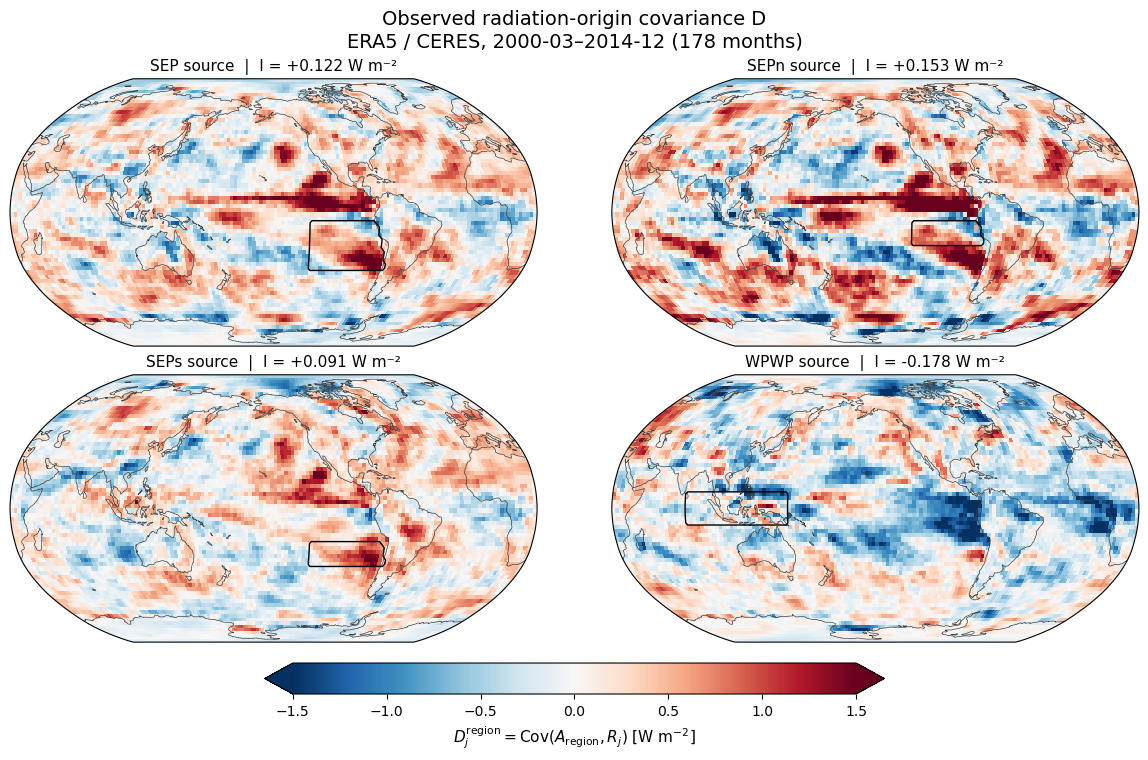

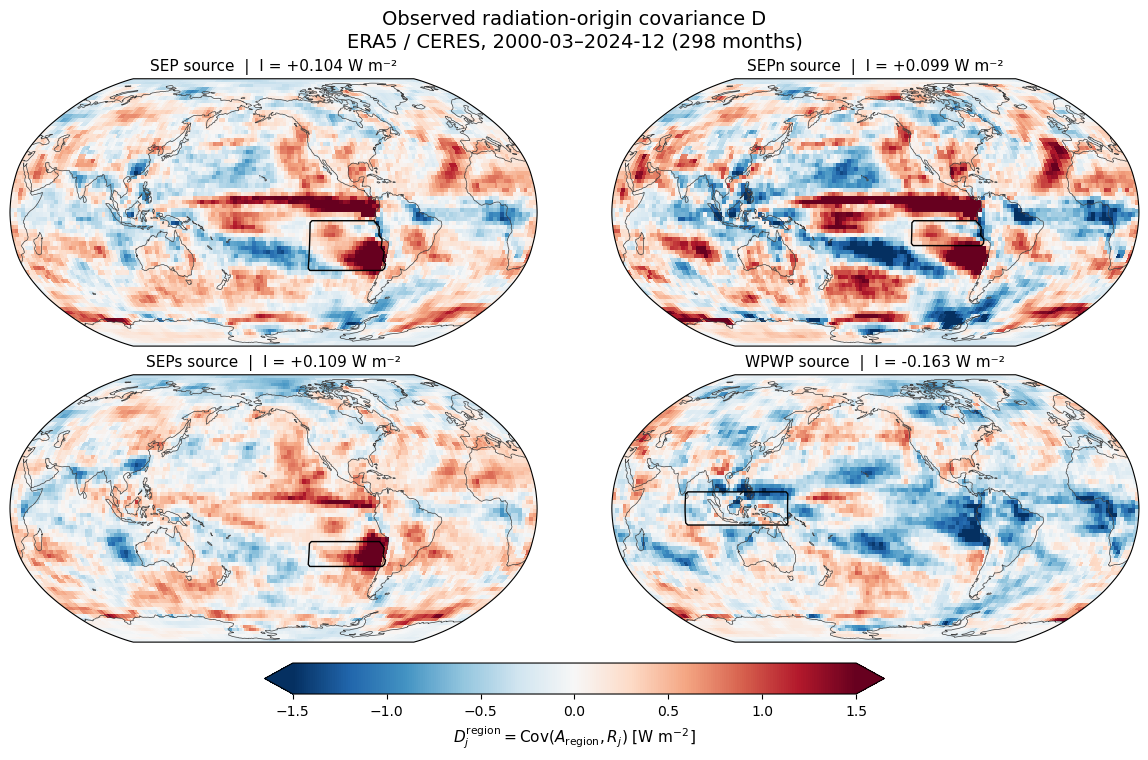

In [7]:
# %% 6. Plot BOTH periods with the same color limits (two separate figures)
# With od_vlim=None, determine ONE limit from all eight maps, not independently
# by panel/period. This makes the colors comparable; colorbar tips show clipping.
if od_vlim is None:
    all_values = np.concatenate([np.asarray(v["D"]).ravel() for period in obs_D_values.values() for v in period.values()])
    finite = np.abs(all_values[np.isfinite(all_values)])
    if not len(finite):
        raise ValueError("No finite D values to plot.")
    od_plot_limit = max(float(np.percentile(finite, 98)), 1e-12)
else:
    od_plot_limit = float(od_vlim)
obs_D_figures, obs_D_axes = {}, {}
for period in od_periods:
    path = od_output_dir / f"figures/observed_D_{period}.png" if od_save_figures else None
    fig, axes = plot_observational_D(obs_D_archive, period, vlim=od_plot_limit, cmap=od_cmap,
                                    central_longitude=od_central_longitude, savepath=path)
    obs_D_figures[period], obs_D_axes[period] = fig, axes
    plt.show()
